# 11 · Time-series prediction and weak signals

Time series break the i.i.d. assumption behind ordinary CV. Three things change:
1. **Features must use only the past.** Easy to violate by accident (centred windows, full-sample normalisation, `bfill`).
2. **Validation must be walk-forward**: train on the past, test on the future, with a **gap** when targets overlap.
3. In finance-like problems the signal is **weak** (R² ≈ 0.01). Then *how big* your predictions are matters as much as their direction.

We simulate two assets: `X` leads `Y` (Y partly follows X's moves over the next few bars), plus lots of noise and changing volatility. The task: predict Y's return over the next 10 bars.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# One consistent, colour-blind-friendly style for every notebook.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 4)

from scipy.signal import lfilter

## 1. Simulate a lead-lag market

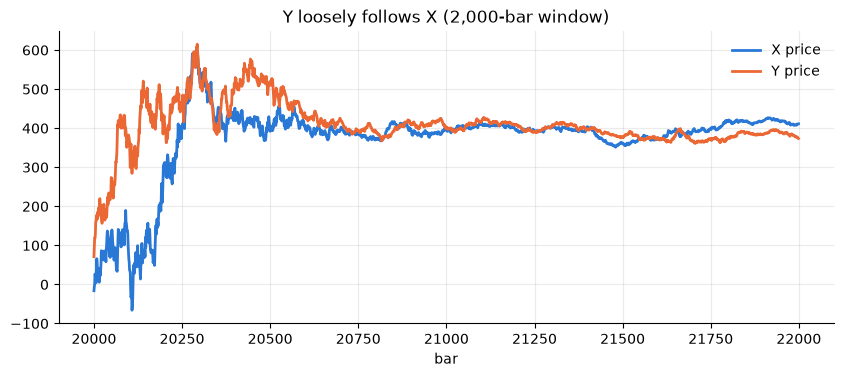

In [2]:
n = 60_000
log_vol = lfilter([0.03], [1, -0.999], rng.normal(size=n))          # slowly drifting volatility regime
vol = np.exp(log_vol)
x_ret = vol * rng.normal(size=n)
lags = np.arange(1, 31)
w = 0.04 * np.exp(-lags / 10)                                          # Y responds to X's last ~30 moves
y_ret = lfilter(np.r_[0, w], [1], x_ret) + vol * rng.normal(size=n)    # + Y's own noise (no own-momentum)

df = pd.DataFrame({"x_ret": x_ret, "y_ret": y_ret})
HORIZON = 10
fig, ax = plt.subplots(figsize=(10, 3.8))
window = slice(20000, 22000)
ax.plot(df["x_ret"].cumsum()[window], label="X price", color=PALETTE[0])
ax.plot(df["y_ret"].cumsum()[window], label="Y price", color=PALETTE[1])
ax.set_xlabel("bar"); ax.legend(); ax.set_title("Y loosely follows X (2,000-bar window)")
plt.show()

## 2. Features from the past, target from the future

- **Target:** sum of Y's next 10 returns, `shift(-1)` … `shift(-10)`. Consecutive targets **overlap** by 9 bars, so neighbouring rows are not independent.
- **Features:** exponentially-weighted momentum of X at several half-lives, Y's own momentum, recent volatility. `ewm(adjust=False)` and `rolling` only look backwards.

In [3]:
feat = pd.DataFrame(index=df.index)
for hl in [2, 8, 32]:
    feat[f"x_mom_{hl}"] = df["x_ret"].ewm(halflife=hl, adjust=False).mean()
feat["y_mom_8"] = df["y_ret"].ewm(halflife=8, adjust=False).mean()
feat["x_vol_100"] = df["x_ret"].rolling(100).std()

target = sum(df["y_ret"].shift(-h) for h in range(1, HORIZON + 1))
data = pd.concat([feat, target.rename("target")], axis=1).dropna()
Xf, yf = data.drop(columns="target"), data["target"]
print(data.shape)
Xf.corrwith(yf).round(4).to_frame("corr with target")

(59891, 6)


,corr with target
x_mom_2,0.1190
x_mom_8,0.0967
x_mom_32,0.0348
y_mom_8,0.0106
x_vol_100,0.0467


Correlations of ~0.1 are what a *strong* signal looks like in this kind of data. Y's own momentum carries almost nothing. `x_vol_100` shows a small correlation, but by construction volatility says nothing about *direction*: that number is an accident of this sample's drift. Watch what it does to a linear model below.

## 3. Two classic leaks

### (a) A feature that peeks: centred rolling window
`rolling(..., center=True)` averages the past *and the future*. It looks like a great feature.

In [4]:
leaky_feature = df["x_ret"].rolling(21, center=True).mean().reindex(data.index)
print(f"corr(honest x_mom_8, target) = {Xf['x_mom_8'].corr(yf):.3f}")
print(f"corr(centred rolling mean, target) = {leaky_feature.corr(yf):.3f}   <- uses future X moves, which Y then follows")

corr(honest x_mom_8, target) = 0.097
corr(centred rolling mean, target) = 0.206   <- uses future X moves, which Y then follows


### (b) Shuffled K-fold on overlapping targets
With shuffled folds, the rows at $t-1$ and $t+1$ (almost the same features, 90% the same target) sit in training while $t$ is validated. A flexible model memorises the neighbourhood.
Walk-forward with a gap ≥ the horizon removes this.

In [5]:
import lightgbm as lgb
from sklearn.model_selection import KFold, TimeSeriesSplit
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def r2_vs_zero(y_true, y_pred):
    # For returns the natural benchmark is predicting 0, not the sample mean.
    return 1 - np.mean((y_true - y_pred) ** 2) / np.mean(y_true ** 2)

def evaluate(model, splitter):
    preds = pd.Series(np.nan, index=yf.index)
    fold_scores = []
    for tr, te in splitter.split(Xf):
        m = model().fit(Xf.iloc[tr], yf.iloc[tr])
        p = m.predict(Xf.iloc[te]); preds.iloc[te] = p
        fold_scores.append(r2_vs_zero(yf.iloc[te].values, p))
    return np.array(fold_scores), preds

flexible_lgbm = lambda: lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=255, min_child_samples=5, verbose=-1, random_state=SEED)
shuffled = KFold(5, shuffle=True, random_state=SEED)
walk_forward = TimeSeriesSplit(n_splits=5, gap=HORIZON)

s_shuf, _ = evaluate(flexible_lgbm, shuffled)
s_wf, _ = evaluate(flexible_lgbm, walk_forward)
print(f"flexible LightGBM | shuffled KFold R²: {s_shuf.mean():+.4f} | walk-forward R²: {s_wf.mean():+.4f}")

flexible LightGBM | shuffled KFold R²: +0.1868 | walk-forward R²: -0.1832


Same model, same data: shuffled CV says it works, walk-forward says it's **worse than predicting zero**.

## 4. Walk-forward comparison: simple vs flexible

`TimeSeriesSplit(gap=HORIZON)` uses an expanding training window and drops `HORIZON` rows between train and test so no training target overlaps the test period.

In [6]:
from sklearn.compose import make_column_transformer
MOMENTUM = ["x_mom_2", "x_mom_8", "x_mom_32", "y_mom_8"]

candidates = {
    "Ridge (all features)": lambda: make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    "Ridge (momentum only)": lambda: make_pipeline(make_column_transformer(("passthrough", MOMENTUM)), StandardScaler(), Ridge(alpha=10.0)),
    "LightGBM (regularised)": lambda: lgb.LGBMRegressor(n_estimators=300, learning_rate=0.02, num_leaves=7, min_child_samples=500,
                                                        subsample=0.7, subsample_freq=1, verbose=-1, random_state=SEED),
    "LightGBM (flexible)": flexible_lgbm,
}
oos = {}
rows = []
for name, mk in candidates.items():
    scores, preds = evaluate(mk, walk_forward)
    oos[name] = preds
    rows.append([name, *scores.round(4), scores.mean().round(4)])
pd.DataFrame(rows, columns=["model", *[f"fold {i+1}" for i in range(5)], "mean"]).set_index("model")

,fold 1,fold 2,fold 3,fold 4,fold 5,mean
model,,,,,,
Ridge (all features),0.0059,0.0055,0.0032,-0.0212,0.0031,-0.0007
Ridge (momentum only),0.0138,0.0095,0.0114,-0.0042,0.0092,0.0080
LightGBM (regularised),-0.0031,0.0080,0.0180,0.0136,0.0046,0.0082
LightGBM (flexible),-0.1197,-0.4774,-0.0647,-0.1253,-0.1287,-0.1832


What this shows:
- **The flexible booster is a disaster** out of sample: with this much noise, capacity goes into fitting noise.
- **Ridge with every feature is worse than Ridge with only the sensible ones.** In a linear model `x_vol_100` becomes a directional bet on volatility, which is pure noise. Trees use it more gracefully (as an interaction: "how big are moves right now"). Feature choice guided by *how the signal should work* matters more than the model.
- The edge is **small and uneven across folds**: every model has a fold at or below zero. That is normal for weak signals; judge on many folds/periods, never one.

When the true relationship is close to linear and the noise is huge, a regularised linear model on well-chosen features matches a carefully regularised booster, with far fewer ways to go wrong. Check it on your own data: plot the average target by decile of a feature or of the prediction. If it's a straight line, go linear.

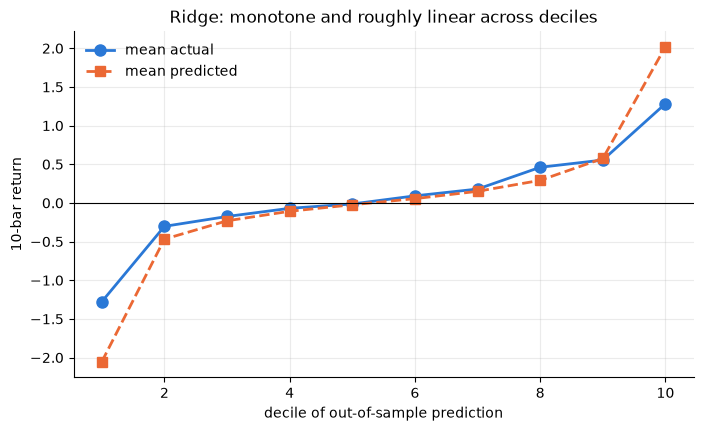

In [7]:
mask = oos["Ridge (momentum only)"].notna()
pred_r = oos["Ridge (momentum only)"][mask]; actual = yf[mask]
dec = pd.qcut(pred_r, 10, labels=False)
by_dec = pd.DataFrame({"pred": pred_r, "actual": actual}).groupby(dec).mean()

fig, ax = plt.subplots()
ax.plot(by_dec.index + 1, by_dec["actual"], "o-", color=PALETTE[0], ms=8, label="mean actual")
ax.plot(by_dec.index + 1, by_dec["pred"], "s--", color=PALETTE[1], ms=7, label="mean predicted")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("decile of out-of-sample prediction"); ax.set_ylabel("10-bar return"); ax.legend()
ax.set_title("Ridge: monotone and roughly linear across deciles")
plt.show()

## 5. Sizing weak predictions

The MSE improvement over predicting zero, when predictions are scaled by $c$:

$$\text{gain}(c) = \mathbb{E}[y^2] - \mathbb{E}[(y - c\hat y)^2] = 2c\,\mathbb{E}[\hat y y] - c^2\,\mathbb{E}[\hat y^2] \quad\Rightarrow\quad c^* = \frac{\mathbb{E}[\hat y y]}{\mathbb{E}[\hat y^2]}$$

So $c^*$ is the out-of-sample slope of $y$ on $\hat y$ (through the origin). If a model's slope is 0.5, its predictions are twice too big, and at $c=1$ it captures *zero* of the possible gain. Correct direction, still useless.

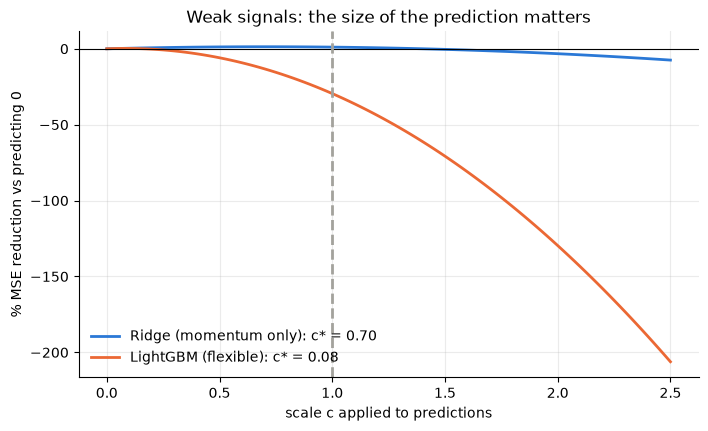

In [8]:
fig, ax = plt.subplots()
cs = np.linspace(0, 2.5, 101)
for k, name in enumerate(["Ridge (momentum only)", "LightGBM (flexible)"]):
    p = oos[name][mask].values; a = actual.values
    gain = [2 * c * np.mean(p * a) - c ** 2 * np.mean(p ** 2) for c in cs]
    c_star = np.mean(p * a) / np.mean(p ** 2)
    ax.plot(cs, np.array(gain) / np.mean(a ** 2) * 100, color=PALETTE[k], label=f"{name}: c* = {c_star:.2f}")
ax.axhline(0, color="black", lw=0.8); ax.axvline(1, color=GREY, ls="--")
ax.set_xlabel("scale c applied to predictions"); ax.set_ylabel("% MSE reduction vs predicting 0"); ax.legend()
ax.set_title("Weak signals: the size of the prediction matters")
plt.show()

In practice estimate $c^*$ from *earlier* walk-forward folds and apply it to later ones. Values a little below 1 (e.g. 0.7–0.9) are common for good models because the signal strength drifts over time, and slightly under-sizing protects the weak periods at little cost in the strong ones.

## 6. Checklist for time-series prediction
- [ ] Every feature computable at time $t$ with data up to $t$ (no `center=True`, no full-sample scaling, no `bfill`)
- [ ] Target defined explicitly with `shift(-h)`; rows at the end with missing targets dropped
- [ ] Walk-forward CV with `gap ≥ horizon`; hyper-parameters chosen inside the training window
- [ ] Benchmark = predicting 0 (returns) or last value / seasonal naive (levels)
- [ ] Check per-fold scores: is the edge stable over time or from one period?
- [ ] Check prediction size (out-of-sample slope); shrink if < 1
- [ ] Watch regime boundaries (session opens, overnight gaps, holidays): reset or mask features there
- [ ] Prefer stationary targets (returns, differences) over levels, since trees can't extrapolate levels